<a href="https://colab.research.google.com/github/diseasemodeling/MIE_525_625/blob/main/Lectures/6a_PINN_Intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Physics-Informed Neural Network (PINN)**
First introduce by Raissa et. al., Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations, Journal of Computational Physics, 2019 https://doi.org/10.1016/j.jcp.2018.10.045

It is a deep learning framework that solves differential equations by embedding laws of physics directly into its training process. Unlike standard neural networks that learn purely from data, a PINN enforces physical constraints—such as conservation laws or biological dynamics—using mathematical equations.

## Key Features
### Inputs and Outputs:
 - The network takes independent variables (like time t or space x) as inputs and directly predicts the state variables  that are  function of those inputs (like population counts or velocity).
    - Generally applicatble to time-space models. time, and space could take many forms
    -  age: disease progression over age
    -  drug concentration or organ volume: concentration of a medication decreases as a function of metabolic processing steps
    - energy, momentum: diffusion of particles
 - Autograd Optimization: It utilizes automatic differentiation (PyTorch/TensorFlow autograd) to calculate exact mathematical derivatives of its own outputs with respect to its inputs.
 ### How the Loss Function Works
 A PINN is trained by minimizing a multi-part loss function that balances observational data with physical reality: $\text{Total Loss}=\text{Loss}_{\text{Data}}+\text{Loss}_{\text{Physics}}+\text{Loss}_{\text{Initial/Boundary}}$
 - Data Loss: Penalizes discrepancies between network predictions and actual collected measurements.
 - Physics Loss (Residual): Evaluates the network's outputs inside the target differential equations.If the network violates the laws of physics, this residual spikes, generating a training penalty.
 - Initial/Boundary Loss: Forces the model to rigidly conform to known starting points or environmental boundaries.

 ### Core Advantages
 - Data Efficient: Requires significantly fewer data points because the embedded physics laws prevent the network from guessing unrealistic solutions.
 - Parameter Discovery: Can solve "inverse problems," allowing it to discover hidden physical constants (say ODE coefficients) automatically from raw observation data.
 - Continuous Solutions: Produces a fully differentiable, mesh-free continuous function capable of evaluating states at any precise coordinate or time step (NN advantage).

# Sample vizual PINN architecture
Seo, J. Solving real-world optimization tasks using physics-informed neural computing. Sci Rep 14, 202 (2024). https://doi.org/10.1038/s41598-023-49977-3

Applied it to
* inverting a pendulum,
* determining the shortest-time path,
* finding the swingby trajectory

![](https://media.springernature.com/full/springer-static/image/art%3A10.1038%2Fs41598-023-49977-3/MediaObjects/41598_2023_49977_Fig1_HTML.png?as=webp)



# EXAMPLE FROM EPIDEMIC

## PROBLEM SETTING (EPIDEMIC EXAMPLE -S,I,R model)
Governing equations of epidmic $$[y_1, y_2, y_3]=[S,I,R]$$
  $$\frac{dS}{dt} = (-\beta  S  I)$$
  $$ \frac{dI}{dt} = (\beta  S  I - \gamma  I)$$
  $$ \frac{dR}{dt} = (\gamma  I)$$

We assume
- We have time series data for S,I, R
- We know the functional forms of $dS/dt, dI/dt, dR/dt$

# Forward problem:
Solve for S, I, R when we have a few sampled data points
* NN architecture:    
    $$t --> [S,I,R]$$
* Physics residuals= (NN estimated derivatives - physics-derive derivative:
$$ r_S= \frac{dS}{dt}- (-\beta  S  I) $$
$$ r_I= \frac{dS}{dt}-  (\beta  S  I - \gamma  I) $$
$$ r_R= \frac{dS}{dt}- (\gamma  I) $$

* Physics Loss $$L_{phy}= r_S^2 + r_I^2+ r_R^2$$


In [ ]:
!pip install -q torchdiffeq

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchdiffeq import odeint # Used only to generate true comparison data
import matplotlib.pyplot as plt

# 1. Define standard MLP network where Input is Time (t) -> Output is States (S, I, R)
class EpiNet(nn.Module):
    def __init__(self):
        super(EpiNet, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 3)
        )

    def forward(self, t):
        return self.net(t)

### Setup known epidemic constants and true data for comparison
The genral setup for PINNs is that we know the initial conditions, any boundary conditions, and actual y data.
In this example, we assume we know these epidemic contants - which are the coefficients in the ODEs. In reality we may not know all of the parameters. In the next example we will assume we do not know and include these as part of the neural network parameters to learn.  

## Data preparartion
train_y below will be replaced by actual data for model training. Here generating synthetic data.

In [ ]:
# Setup known epidemic constants and true data for comparison
beta, gamma = 0.4, 0.1 # In this example, we assume we know these parameters- which are the coefficients in the ODEs.
initial_state = torch.tensor([0.99, 0.01, 0.00])

# Actual data available for training: suppose we only have data for these timesteps
t_data = torch.tensor([15., 16., 18., 20.]).unsqueeze(dim=1)

#------------------
# Generate a dense set of physics collocation points, ensuring t_data points are included
t_physics_base = torch.linspace(0., 50., 200).view(-1)
t_physics_combined = torch.unique(torch.cat((t_physics_base, t_data.view(-1)))).sort().values# Combine with t_data points to ensure exact matches are present#
t_physics = t_physics_combined.view(-1, 1).requires_grad_(True)# Convert to a column vector and enable gradient tracking for physics loss

#------------------
# Compute true_y for validation: True y is not typically available - creating here for demonstration.
def true_sir_dynamics(t, y):
    S, I, R = y[0], y[1], y[2]
    return torch.stack([-beta*S*I, beta*S*I - gamma*I, gamma*I])
true_y = odeint(true_sir_dynamics, initial_state, t_physics.detach().view(-1))

#------------------
# Extract train_y by finding the exact indices of t_data within t_physics
time_mask = torch.isin(t_physics.detach().view(-1), t_data.view(-1))
matching_indices = torch.nonzero(time_mask).squeeze()
train_y = true_y[matching_indices, :]

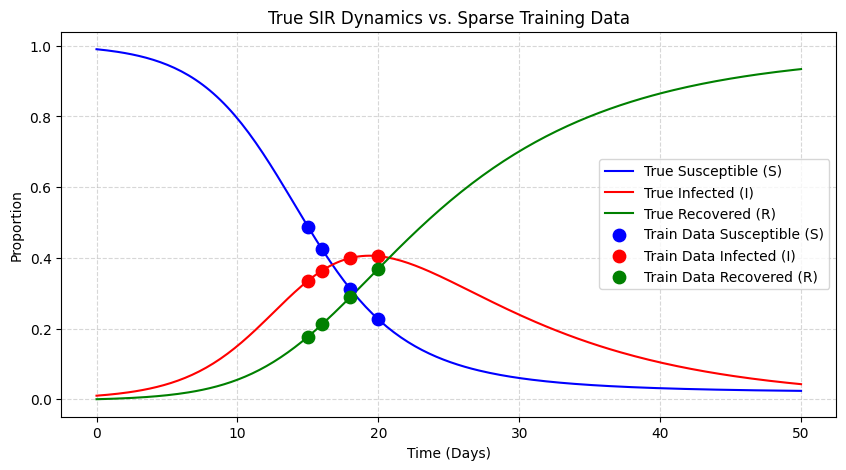

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
labels = ['Susceptible (S)', 'Infected (I)', 'Recovered (R)']
colors = ['blue', 'red', 'green']

# Plot continuous ground truth
for i in range(3):
    plt.plot(t_physics.detach().numpy(), true_y[:, i].numpy(), label=f'True {labels[i]}', color=colors[i], linestyle='-')

# Plot sparse training data points
for i in range(3):
    plt.scatter(t_data.numpy(), train_y[:, i].numpy(), label=f'Train Data {labels[i]}', color=colors[i], s=80, zorder=5)

plt.title('True SIR Dynamics vs. Sparse Training Data')
plt.xlabel('Time (Days)')
plt.ylabel('Proportion')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### PINN TRAIN

In [ ]:
epi_pinn = EpiNet()
optimizer = optim.Adam(epi_pinn.parameters(), lr=0.001)

In [ ]:
epochs = 500
for epoch in range(epochs):
    optimizer.zero_grad()

    # -------------------------------------------------------------------------
    # 1. DATA LOSS (Comparing sparse model predictions against actual measurements)
    # -------------------------------------------------------------------------
    pred_data = epi_pinn(t_data)
    loss_data = torch.mean((pred_data - train_y) ** 2)

    # -------------------------------------------------------------------------
    # 2. PHYSICS LOSS (Using a denser grid of collocation points to enforce laws)
    # -------------------------------------------------------------------------
    pred_phys = epi_pinn(t_physics)
    S_p, I_p, R_p = pred_phys[:, 0:1], pred_phys[:, 1:2], pred_phys[:, 2:3]

    # Compute derivatives from predicted values via autograd
    dS_dt = torch.autograd.grad(S_p, t_physics, torch.ones_like(S_p), create_graph=True)[0]
    dI_dt = torch.autograd.grad(I_p, t_physics, torch.ones_like(I_p), create_graph=True)[0]
    dR_dt = torch.autograd.grad(R_p, t_physics, torch.ones_like(R_p), create_graph=True)[0]

    # Physics residuals (NN estimated derivatives - physics-derive derivative
    f_S = dS_dt - (-beta * S_p * I_p)
    f_I = dI_dt - (beta * S_p * I_p - gamma * I_p)
    f_R = dR_dt - (gamma * I_p)
    loss_physics = torch.mean(f_S**2) + torch.mean(f_I**2) + torch.mean(f_R**2)

    # -------------------------------------------------------------------------
    # 3. INITIAL CONDITION LOSS
    # -------------------------------------------------------------------------
    t_zero = torch.tensor([[0.0]])
    pred_zero = epi_pinn(t_zero)
    loss_initial = torch.mean((pred_zero - initial_state)**2)

    # -------------------------------------------------------------------------
    # TOTAL LOSS: Balances observations + structural physics constraints
    # -------------------------------------------------------------------------
    total_loss = 1 * loss_data + 2.0 * loss_physics + 1 * loss_initial

    total_loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch} | Data Loss: {loss_data.item():.6f} | Physics Loss: {loss_physics.item():.6f}")

epi_pinn.eval()
with torch.no_grad():
    pred_y_PINN = epi_pinn(t_physics) #predict for full time range

Epoch 0 | Data Loss: 0.334250 | Physics Loss: 0.008391


## Regular NN train (not PINN)- only use data loss- use for comparing with PINN

In [ ]:
epi_nn = EpiNet()
optimizer = optim.Adam(epi_nn.parameters(), lr=0.001)
epochs = 500
for epoch in range(epochs):
    optimizer.zero_grad()

    # -------------------------------------------------------------------------
    # 1. DATA LOSS (Comparing sparse model predictions against actual measurements)
    # -------------------------------------------------------------------------
    pred_data = epi_nn(t_data)
    loss_data = torch.mean((pred_data - train_y) ** 2)

    total_loss = 1 * loss_data
    total_loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch} | Data Loss: {loss_data.item():.6f}")
epi_nn.eval()
with torch.no_grad():
    pred_y_NN = epi_nn(t_physics) #predict for full time range

Epoch 0 | Data Loss: 0.147073


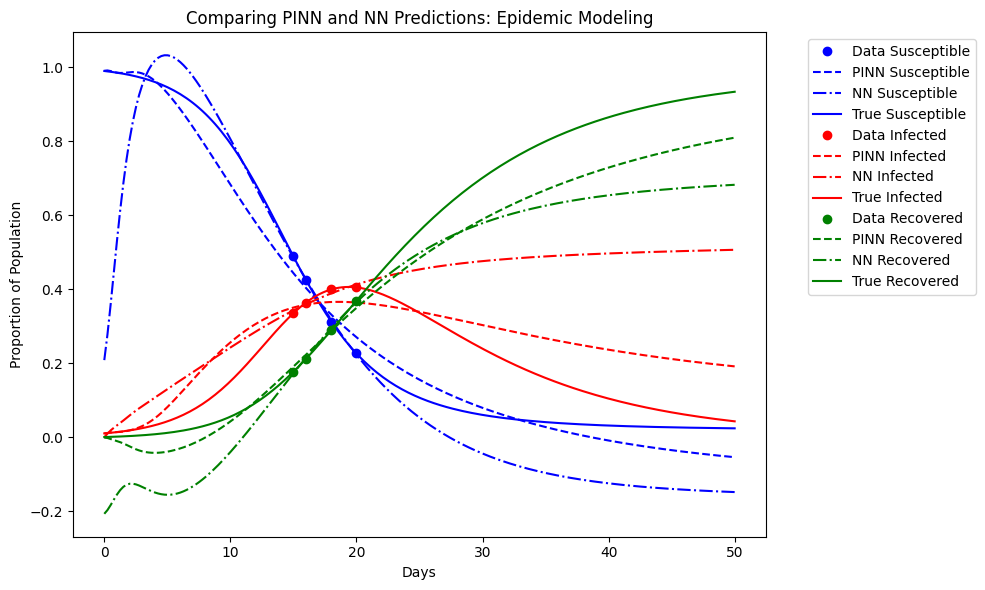

In [ ]:
# Plot  Predictions vs Ground Truth
plt.figure(figsize=(10, 6))
labels = ['Susceptible', 'Infected', 'Recovered']
colors = ['blue', 'red', 'green']

for i in range(3):
    plt.plot(t_data.numpy(), train_y[:, i].numpy(), label=f'Data {labels[i]}', color=colors[i], marker='o', linestyle='None' )
    plt.plot(t_physics.detach().numpy(), pred_y_PINN[:, i].numpy(), label=f'PINN {labels[i]}', color=colors[i], linestyle='--')
    plt.plot(t_physics.detach().numpy(), pred_y_NN[:, i].numpy(), label=f'NN {labels[i]}', color=colors[i], linestyle='-.')
    plt.plot(t_physics.detach().numpy(), true_y[:, i].numpy(), label=f'True {labels[i]}', color=colors[i])
plt.title('Comparing PINN and NN Predictions: Epidemic Modeling')
plt.xlabel('Days')
plt.ylabel('Proportion of Population')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()